# SMT-LIB 2025: feature distributions

This notebook analyses all benchmarks from the ten selected SMT-LIB 2025
non-incremental logic archives. One row is one `.smt2` solver input. The raw
157-position `ksmt-machsmt-inspired-v1` vector is preserved. Structural
features use `NaN` when safe AST extraction was not possible.

The goal is to understand dataset balance, feature sparsity, theory separation,
and leakage risks before training a cvc5 configuration selector.

In [1]:
from pathlib import Path
import hashlib
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 40)

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_PATH = ROOT / "data/processed/smtlib-2025-features.csv.gz"
SCHEMA_PATH = ROOT / "data/processed/smtlib-2025-features.schema.csv"
MANIFEST_PATH = ROOT / "data/processed/smtlib-2025-features.manifest.json"
FIGURE_DIR = ROOT / "reports/feature-distributions"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def finish_figure(name):
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / name, dpi=160, bbox_inches="tight")
    plt.show()


## Load and validate

In [2]:
manifest = json.loads(MANIFEST_PATH.read_text())
assert manifest["status"] == "complete"
assert sha256_file(DATA_PATH) == manifest["outputSha256"]
assert sha256_file(SCHEMA_PATH) == manifest["schemaSha256"]

df = pd.read_csv(DATA_PATH, compression="gzip", low_memory=False)
schema = pd.read_csv(SCHEMA_PATH)
feature_columns = schema["name"].tolist()
name_by_id = schema.set_index("id")["name"].to_dict()
cluster_by_feature = schema.set_index("name")["cluster"].to_dict()

assert len(feature_columns) == 157
assert schema["schema_version"].nunique() == 1
assert schema["schema_version"].iat[0] == "ksmt-machsmt-inspired-v1"
assert set(feature_columns).issubset(df.columns)
assert df["relative_path"].is_unique
assert df["feature_schema"].nunique() == 1
assert df["feature_schema"].iat[0] == schema["schema_version"].iat[0]
assert manifest["featureSchema"] == df["feature_schema"].iat[0]
assert manifest["datasetId"] == df["dataset_id"].iat[0]
assert df["benchmark_sha256"].str.fullmatch(r"[0-9a-f]{64}").all()

provenance = pd.Series({
    "dataset_id": manifest["datasetId"],
    "feature_schema": manifest["featureSchema"],
    "code_revision": manifest["codeRevision"],
    "input_manifest_sha256": manifest["inputManifestSha256"],
    "feature_table_sha256": manifest["outputSha256"],
    "schema_sha256": manifest["schemaSha256"],
})
overview = pd.Series({
    "benchmarks": len(df),
    "logics": df["logic"].nunique(),
    "families": df[["logic", "family"]].drop_duplicates().shape[0],
    "full AST rows": (df["extraction_status"] == "ok").sum(),
    "syntax-only rows": (df["extraction_status"] == "partial").sum(),
    "failed rows": (df["extraction_status"] == "error").sum(),
})
display(provenance.to_frame("value"))
display(overview.to_frame("value"))
display(df.head(3))


,value
dataset_id,smtlib-2025-ten-archive-v1
feature_schema,ksmt-machsmt-inspired-v1
code_revision,fa7d3c5e45bbe57bfef59a6fd3db5a53180f8c69
input_manifest_sha256,d8d67d9881e7f4aa95c9bb076e5b0d0a92d9aaaf237375...
feature_table_sha256,6e9e01b60faa1a9a67eef96ceb0dca3c7f0697217f25c2...
schema_sha256,f85f49903319cc6c879733d602ef7d97ca248975bb7563...


,value
benchmarks,64432
logics,10
families,57
full AST rows,64341
syntax-only rows,91
failed rows,0


,dataset_id,feature_schema,benchmark_sha256,relative_path,logic,family,expected_status,extraction_status,error,f001_as,f002_assert,f003_check-sat,f004_check-sat-assuming,f005_declare-const,f006_declare-datatype,f007_declare-datatypes,f008_declare-fun,f009_declare-sort,f010_define-fun,f011_define-fun-rec,...,f138_lteq,f139_lt,f140_gteq,f141_gt,f142_to-real,f143_to-int,f144_is-int,f145_real,f146_average-selects-per-array,f147_average-store-chain-depth,f148_bv-adder-chain-mean,f149_bv-adder-chain-median,f150_bv-adder-chain-population-deviation,f151_forall-bound-variables,f152_exists-bound-variables,f153_exists-to-forall-variable-ratio,f154_average-quantifier-nesting,f155_average-applied-uf-arity,f156_average-applications-per-applied-uf,f157_source-size-bytes
0,smtlib-2025-ten-archive-v1,ksmt-machsmt-inspired-v1,1d3b860c9260cc88d68276c7bdc02c6b673ebce47b9204...,LIA/20190429-UltimateAutomizerSvcomp2019/jain_...,LIA,20190429-UltimateAutomizerSvcomp2019,unsat,ok,NaN,0.0,3.0,1.0,0.0,0.0,0.0,0.0,6.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,1.0,0.0,0.0,2282.0
1,smtlib-2025-ten-archive-v1,ksmt-machsmt-inspired-v1,b743a8c745a2603406587f39a869dac5d9f16b405539a1...,LIA/20190429-UltimateAutomizerSvcomp2019/jain_...,LIA,20190429-UltimateAutomizerSvcomp2019,unsat,ok,NaN,0.0,2.0,1.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,10.0,0.0,1.0,0.0,0.0,2297.0
2,smtlib-2025-ten-archive-v1,ksmt-machsmt-inspired-v1,677a321556ff58d5a5aaab27e50c96a6334d3526f6a804...,LIA/20190429-UltimateAutomizerSvcomp2019/jain_...,LIA,20190429-UltimateAutomizerSvcomp2019,unsat,ok,NaN,0.0,2.0,1.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,12.0,0.0,1.0,0.0,0.0,2409.0


## Dataset composition and extraction quality

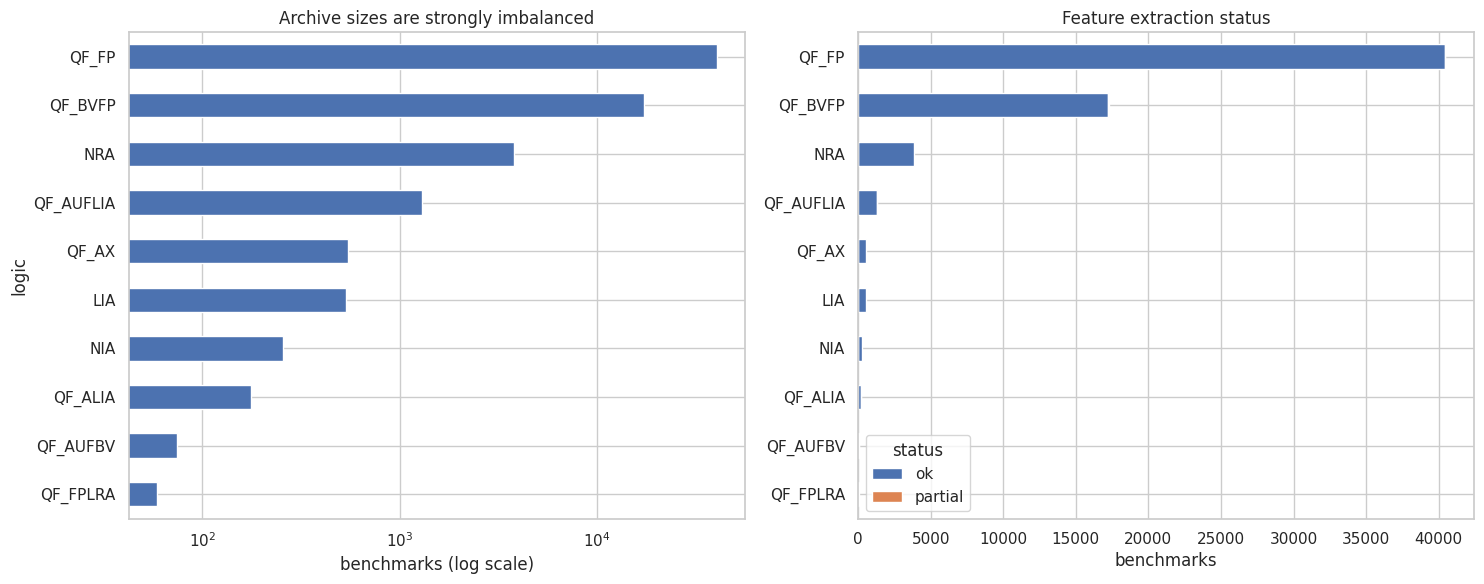

extraction_status,ok,partial,total
logic,,,
QF_FP,40400,6,40406
QF_BVFP,17231,19,17250
NRA,3819,0,3819
QF_AUFLIA,1279,24,1303
QF_AX,551,0,551
LIA,536,0,536
NIA,257,0,257
QF_ALIA,170,6,176
QF_AUFBV,39,36,75


In [3]:
logic_counts = df["logic"].value_counts().sort_values()
status_by_logic = pd.crosstab(df["logic"], df["extraction_status"])

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
logic_counts.plot.barh(ax=axes[0], color=sns.color_palette()[0])
axes[0].set_xscale("log")
axes[0].set_xlabel("benchmarks (log scale)")
axes[0].set_ylabel("logic")
axes[0].set_title("Archive sizes are strongly imbalanced")

status_by_logic.reindex(logic_counts.index).plot.barh(stacked=True, ax=axes[1])
axes[1].set_xlabel("benchmarks")
axes[1].set_ylabel("")
axes[1].set_title("Feature extraction status")
axes[1].legend(title="status")
finish_figure("01_dataset_composition.png")

display(status_by_logic.assign(total=status_by_logic.sum(axis=1)).sort_values("total", ascending=False))


## Feature availability, variance, and sparsity

,features,median_available_rate,median_nonzero_rate,nonconstant_features
cluster,,,,
source-metadata,1,1.000000,1.000000,1
problem-commands,4,1.000000,0.499984,1
quantifiers-and-bindings,7,0.998588,0.065542,7
boolean-core,11,1.000000,0.064223,10
floating-point,46,1.000000,0.043891,38
arithmetic,15,1.000000,0.035169,11
arrays,5,1.000000,0.021402,5
uninterpreted-functions,2,0.998588,0.012556,2
bit-vectors,39,1.000000,0.000512,32


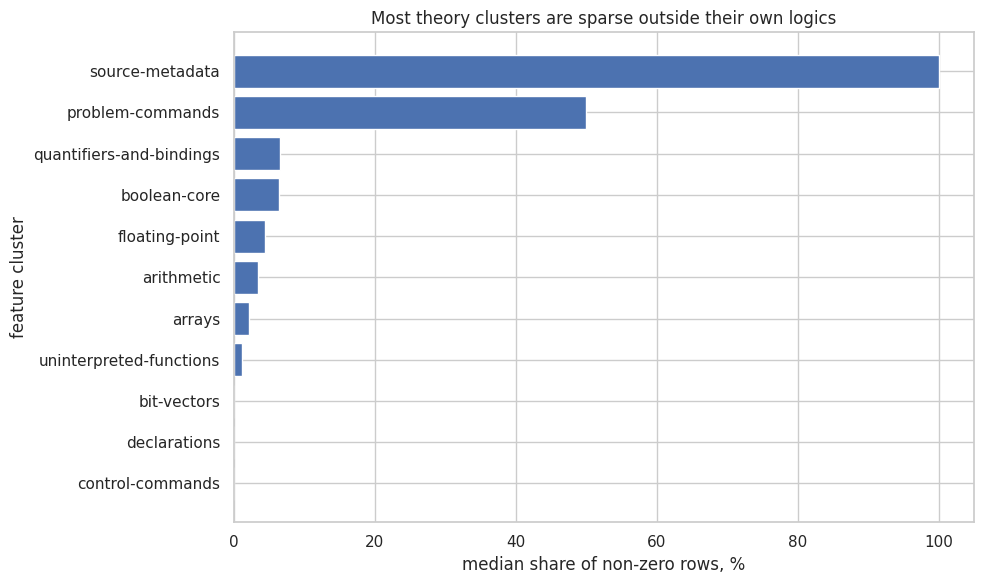

,schema_version,id,name,cluster,value_type,missing_value,available_rate,nonzero_rate,variance,median,p95,max
156,ksmt-machsmt-inspired-v1,157,f157_source-size-bytes,source-metadata,double,NaN,1.0,1.000000,3.228886e+08,1328.0,2639.45,2388152.0
28,ksmt-machsmt-inspired-v1,29,f029_set-info,control-commands,double,NaN,1.0,1.000000,2.024668e-01,4.0,5.00,5.0
2,ksmt-machsmt-inspired-v1,3,f003_check-sat,problem-commands,double,NaN,1.0,1.000000,0.000000e+00,1.0,1.00,1.0
14,ksmt-machsmt-inspired-v1,15,f015_exit,control-commands,double,NaN,1.0,1.000000,0.000000e+00,1.0,1.00,1.0
29,ksmt-machsmt-inspired-v1,30,f030_set-logic,control-commands,double,NaN,1.0,1.000000,0.000000e+00,1.0,1.00,1.0
1,ksmt-machsmt-inspired-v1,2,f002_assert,problem-commands,double,NaN,1.0,0.999969,7.382704e+03,3.0,13.00,3525.0
7,ksmt-machsmt-inspired-v1,8,f008_declare-fun,declarations,double,NaN,1.0,0.998820,1.163276e+03,3.0,20.00,3378.0
41,ksmt-machsmt-inspired-v1,42,f042_eq,boolean-core,double,NaN,1.0,0.733828,1.011053e+04,3.0,8.00,5653.0
36,ksmt-machsmt-inspired-v1,37,f037_not,boolean-core,double,NaN,1.0,0.685638,6.031205e+03,1.0,9.00,1979.0
85,ksmt-machsmt-inspired-v1,86,f086_floatingpoint,floating-point,double,NaN,1.0,0.628259,5.267398e+02,1.0,1.00,2292.0


In [4]:
usable = df[df["extraction_status"] != "error"].copy()
X = usable[feature_columns].replace(-1.0, np.nan)

feature_stats = schema.copy()
feature_stats["available_rate"] = X.notna().mean().reindex(feature_columns).to_numpy()
feature_stats["nonzero_rate"] = X.fillna(0).ne(0).mean().reindex(feature_columns).to_numpy()
feature_stats["variance"] = X.var().reindex(feature_columns).to_numpy()
feature_stats["median"] = X.median().reindex(feature_columns).to_numpy()
feature_stats["p95"] = X.quantile(0.95).reindex(feature_columns).to_numpy()
feature_stats["max"] = X.max().reindex(feature_columns).to_numpy()

cluster_stats = feature_stats.groupby("cluster").agg(
    features=("id", "size"),
    median_available_rate=("available_rate", "median"),
    median_nonzero_rate=("nonzero_rate", "median"),
    nonconstant_features=("variance", lambda s: int((s.fillna(0) > 0).sum())),
).sort_values("median_nonzero_rate", ascending=False)
display(cluster_stats)

fig, ax = plt.subplots(figsize=(10, 6))
plot_stats = cluster_stats.sort_values("median_nonzero_rate")
ax.barh(plot_stats.index, plot_stats["median_nonzero_rate"] * 100)
ax.set_xlabel("median share of non-zero rows, %")
ax.set_ylabel("feature cluster")
ax.set_title("Most theory clusters are sparse outside their own logics")
finish_figure("02_cluster_sparsity.png")

display(feature_stats.sort_values(["nonzero_rate", "variance"], ascending=False).head(25))


## Logic signatures by feature cluster

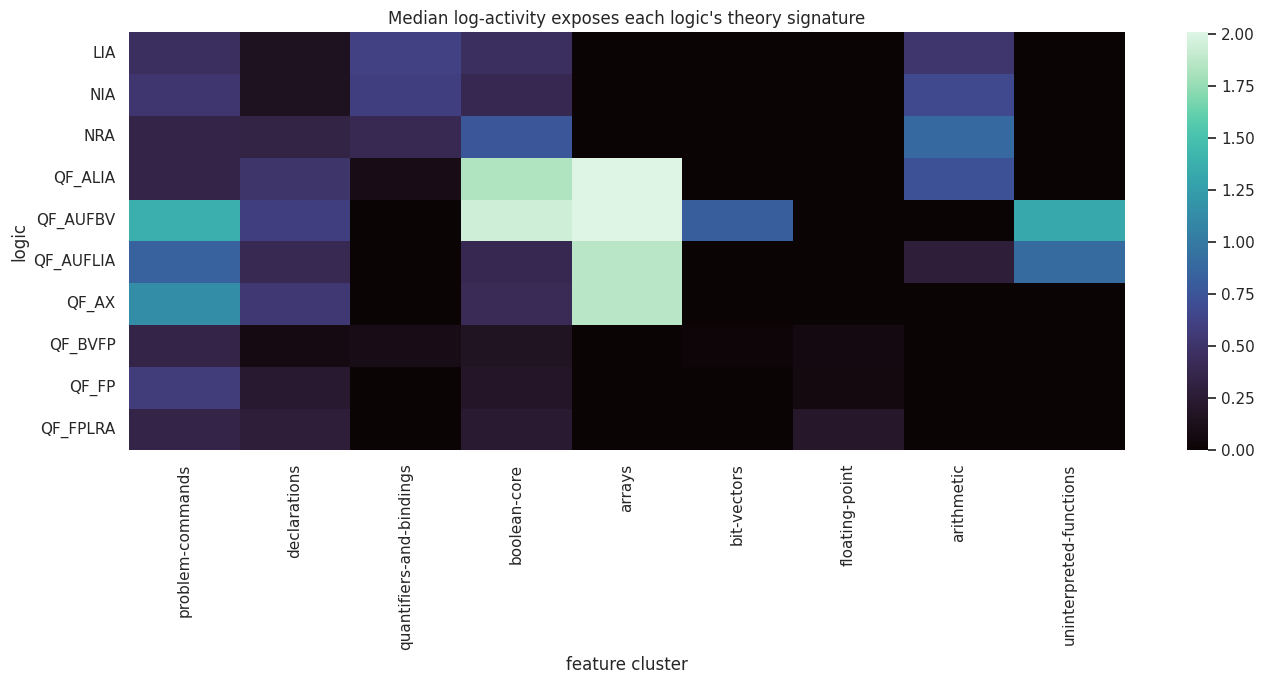

In [5]:
analysis_clusters = [
    c for c in schema["cluster"].unique()
    if c not in {"source-metadata", "control-commands"}
]

cluster_activity = pd.DataFrame(index=usable.index)
for cluster in analysis_clusters:
    columns = schema.loc[schema["cluster"] == cluster, "name"]
    values = usable[columns].replace(-1.0, np.nan).clip(lower=0)
    cluster_activity[cluster] = np.log1p(values).mean(axis=1)
cluster_activity["logic"] = usable["logic"]

logic_cluster_medians = cluster_activity.groupby("logic").median()
fig, ax = plt.subplots(figsize=(14, 7))
sns.heatmap(logic_cluster_medians, cmap="mako", ax=ax, robust=True)
ax.set_xlabel("feature cluster")
ax.set_ylabel("logic")
ax.set_title("Median log-activity exposes each logic's theory signature")
finish_figure("03_logic_cluster_heatmap.png")


## Selected feature distributions

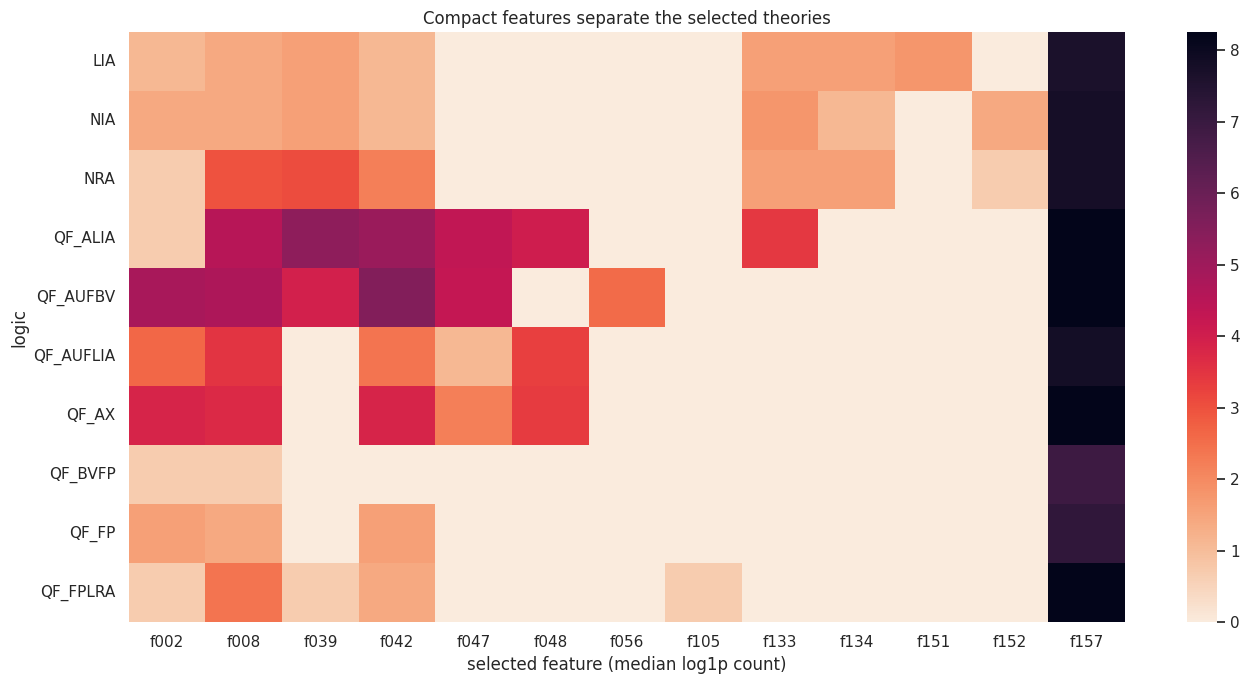

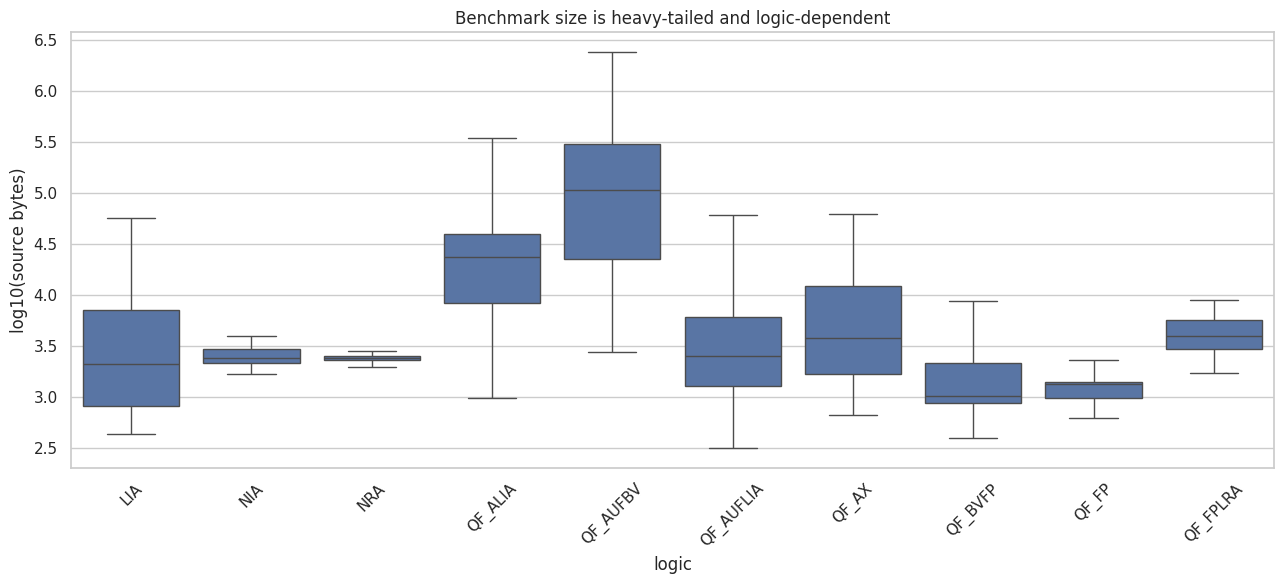

In [6]:
selected_ids = [2, 8, 39, 42, 47, 48, 56, 105, 133, 134, 151, 152, 157]
selected = [name_by_id[i] for i in selected_ids]
selected_medians = (
    usable.groupby("logic")[selected]
    .median()
    .clip(lower=0)
    .pipe(np.log1p)
)
selected_medians.columns = [f"f{i:03d}" for i in selected_ids]

fig, ax = plt.subplots(figsize=(14, 7))
sns.heatmap(selected_medians, cmap="rocket_r", ax=ax, robust=True, annot=False)
ax.set_xlabel("selected feature (median log1p count)")
ax.set_ylabel("logic")
ax.set_title("Compact features separate the selected theories")
finish_figure("04_selected_feature_heatmap.png")

size_feature = name_by_id[157]
fig, ax = plt.subplots(figsize=(13, 6))
size_plot = usable[["logic", size_feature]].copy()
size_plot["log10_bytes"] = np.log10(size_plot[size_feature].clip(lower=1))
sns.boxplot(data=size_plot, x="logic", y="log10_bytes", showfliers=False, ax=ax)
ax.tick_params(axis="x", rotation=45)
ax.set_xlabel("logic")
ax.set_ylabel("log10(source bytes)")
ax.set_title("Benchmark size is heavy-tailed and logic-dependent")
finish_figure("05_source_size_by_logic.png")


## Two-dimensional view of the feature space

,ratio
PC1 explained variance,0.102824
PC2 explained variance,0.090729
two-component total,0.193553


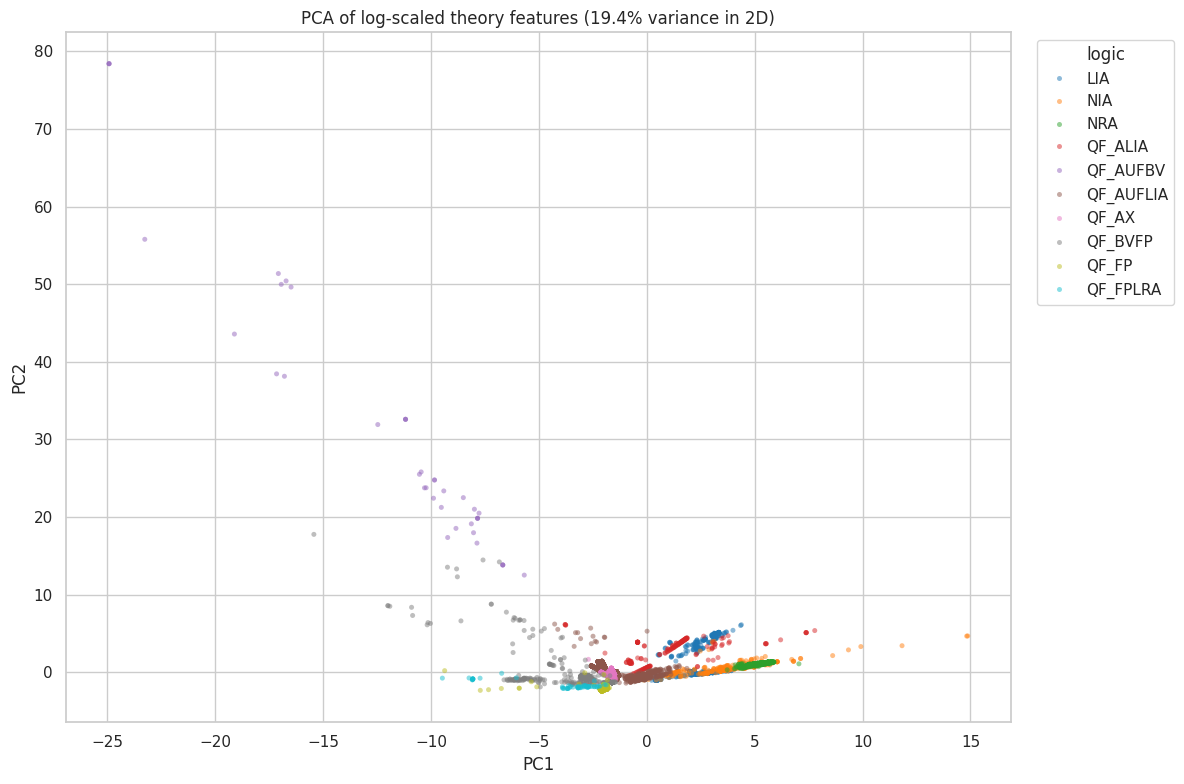

In [7]:
model_clusters = {
    "declarations", "quantifiers-and-bindings", "boolean-core", "arrays",
    "bit-vectors", "floating-point", "arithmetic", "uninterpreted-functions",
}
model_features = schema.loc[schema["cluster"].isin(model_clusters), "name"].tolist()
full_ast = df[df["extraction_status"] == "ok"].copy()
sampled = pd.concat([
    group.sample(min(len(group), 1_500), random_state=42)
    for _, group in full_ast.groupby("logic")
], ignore_index=True)

Xp = sampled[model_features].replace(-1.0, np.nan).clip(lower=0).pipe(np.log1p)
variable = Xp.columns[Xp.nunique(dropna=True) > 1]
pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    PCA(n_components=2, random_state=42),
)
embedding = pipeline.fit_transform(Xp[variable])
pca = pipeline.named_steps["pca"]
pca_df = pd.DataFrame({"PC1": embedding[:, 0], "PC2": embedding[:, 1], "logic": sampled["logic"]})
display(pd.Series({
    "PC1 explained variance": pca.explained_variance_ratio_[0],
    "PC2 explained variance": pca.explained_variance_ratio_[1],
    "two-component total": pca.explained_variance_ratio_.sum(),
}).to_frame("ratio"))

fig, ax = plt.subplots(figsize=(12, 8))
sns.scatterplot(
    data=pca_df, x="PC1", y="PC2", hue="logic", s=13, alpha=0.5,
    linewidth=0, palette="tab10", ax=ax,
)
ax.set_title(
    f"PCA of log-scaled theory features "
    f"({pca.explained_variance_ratio_.sum():.1%} variance in 2D)"
)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="logic")
finish_figure("06_feature_pca.png")


## Family structure and leakage risk

,families,largest_family,total,largest_family_share
logic,,,,
QF_FP,8,39994,40406,0.989803
QF_BVFP,8,17156,17250,0.994551
NRA,3,3813,3819,0.998429
QF_AUFLIA,7,648,1303,0.497314
QF_AX,4,302,551,0.548094
LIA,5,189,536,0.352612
NIA,5,197,257,0.766537
QF_ALIA,6,52,176,0.295455
QF_AUFBV,6,31,75,0.413333


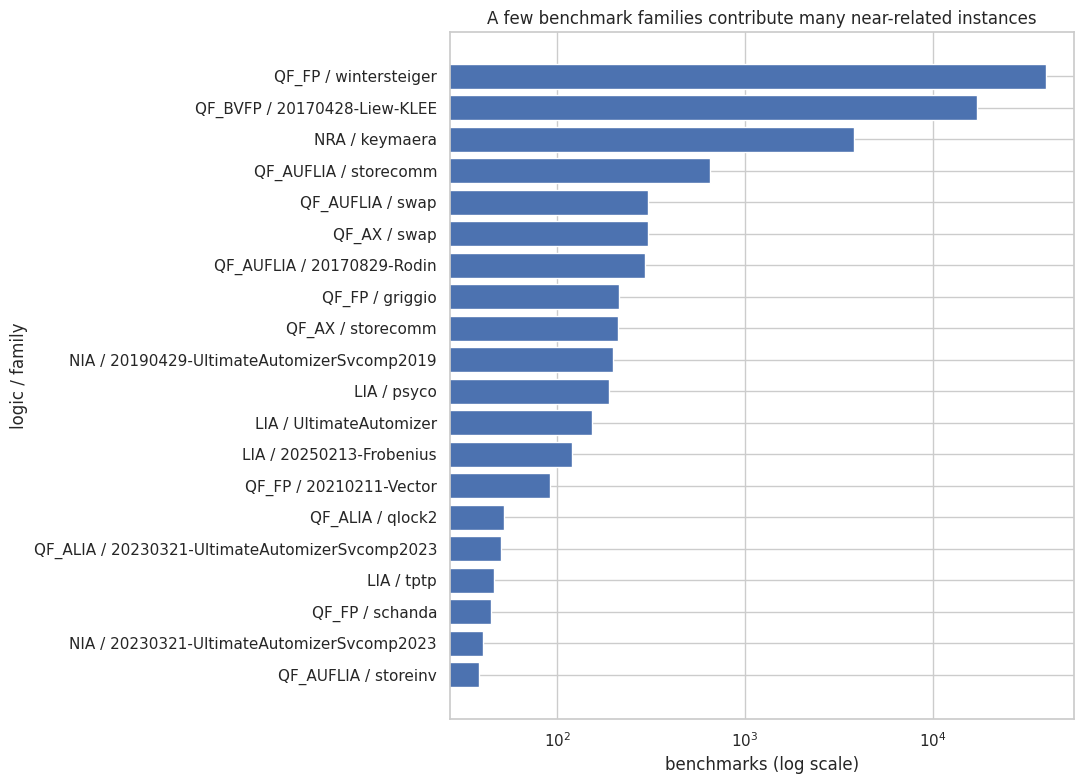

In [8]:
family_counts = df.groupby(["logic", "family"]).size().rename("benchmarks").reset_index()
logic_family_summary = family_counts.groupby("logic").agg(
    families=("family", "nunique"),
    largest_family=("benchmarks", "max"),
    total=("benchmarks", "sum"),
)
logic_family_summary["largest_family_share"] = (
    logic_family_summary["largest_family"] / logic_family_summary["total"]
)
display(logic_family_summary.sort_values("total", ascending=False))

top_families = family_counts.nlargest(20, "benchmarks").sort_values("benchmarks")
fig, ax = plt.subplots(figsize=(11, 8))
labels = top_families["logic"] + " / " + top_families["family"].replace("", "<root>")
ax.barh(labels, top_families["benchmarks"])
ax.set_xscale("log")
ax.set_xlabel("benchmarks (log scale)")
ax.set_ylabel("logic / family")
ax.set_title("A few benchmark families contribute many near-related instances")
finish_figure("07_largest_families.png")


## Pilot cohort and exact-content overlap

In [9]:
pilot_logics = ["QF_ALIA", "QF_AUFLIA", "LIA"]
pilot = df[df["logic"].isin(pilot_logics)].copy()
pilot_family_counts = (
    pilot.groupby(["logic", "family"]).size().rename("benchmarks").reset_index()
)
pilot_summary = pilot.groupby("logic").agg(
    benchmarks=("relative_path", "size"),
    families=("family", "nunique"),
    full_ast=("extraction_status", lambda s: int((s == "ok").sum())),
    syntax_only=("extraction_status", lambda s: int((s == "partial").sum())),
    sat=("expected_status", lambda s: int((s == "sat").sum())),
    unsat=("expected_status", lambda s: int((s == "unsat").sum())),
    unknown=("expected_status", lambda s: int((s == "unknown").sum())),
)
largest_pilot_family = pilot_family_counts.groupby("logic")["benchmarks"].max()
pilot_summary["largest_family_share"] = (
    largest_pilot_family / pilot_summary["benchmarks"]
)
display(pilot_summary)

content_multiplicity = df.groupby("benchmark_sha256").size()
pilot_content_multiplicity = pilot.groupby("benchmark_sha256").size()
display(pd.Series({
    "corpus duplicate hash groups": int((content_multiplicity > 1).sum()),
    "corpus rows in duplicate hash groups": int(content_multiplicity[content_multiplicity > 1].sum()),
    "pilot duplicate hash groups": int((pilot_content_multiplicity > 1).sum()),
    "pilot rows in duplicate hash groups": int(
        pilot_content_multiplicity[pilot_content_multiplicity > 1].sum()
    ),
}).to_frame("count"))


,benchmarks,families,full_ast,syntax_only,sat,unsat,unknown,largest_family_share
logic,,,,,,,,
LIA,536,5,536,0,270,266,0,0.352612
QF_ALIA,176,6,170,6,54,72,50,0.295455
QF_AUFLIA,1303,7,1279,24,543,760,0,0.497314


,count
corpus duplicate hash groups,3
corpus rows in duplicate hash groups,6
pilot duplicate hash groups,0
pilot rows in duplicate hash groups,0


## Redundancy and initial feature-selection diagnostics

In [10]:
candidate_features = schema.loc[
    ~schema["cluster"].isin({"control-commands"}), "name"
].tolist()
candidate_matrix = usable[candidate_features].replace(-1.0, np.nan)
zero_variance = candidate_matrix.columns[candidate_matrix.nunique(dropna=False) <= 1].tolist()
duplicate_mask = candidate_matrix.fillna(-999_999).T.duplicated()
duplicate_features = candidate_matrix.columns[duplicate_mask].tolist()

diagnostics = pd.Series({
    "raw features": len(feature_columns),
    "candidate features": len(candidate_features),
    "zero-variance candidates": len(zero_variance),
    "exact duplicate candidates": len(duplicate_features),
    "remaining after mechanical filters": (
        len(candidate_features) - len(set(zero_variance) | set(duplicate_features))
    ),
})
display(diagnostics.to_frame("count"))
display(pd.DataFrame({
    "zero_variance": pd.Series(zero_variance),
    "exact_duplicate": pd.Series(duplicate_features),
}))


,count
raw features,157
candidate features,139
zero-variance candidates,27
exact duplicate candidates,25
remaining after mechanical filters,112


,zero_variance,exact_duplicate
0,f001_as,f004_check-sat-assuming
1,f003_check-sat,f006_declare-datatype
2,f004_check-sat-assuming,f007_declare-datatypes
3,f006_declare-datatype,f011_define-fun-rec
4,f007_declare-datatypes,f012_define-funs-rec
5,f011_define-fun-rec,f041_xor
6,f012_define-funs-rec,f063_bvnand
7,f041_xor,f064_bvnor
8,f063_bvnand,f066_bvxnor
9,f064_bvnor,f067_bvcomp


## Interpretation checklist

1. Treat each `.smt2` file as one non-incremental solver query, but treat
   `(logic, family)` as the independent grouping unit for evaluation.
2. Quantify logic and family imbalance before choosing a primary study cohort.
3. Resolve exact-content duplicates before assigning families to splits, then
   assess near-duplicate risk within the reviewed pilot cohort.
4. Use `log1p`, robust scaling, or tree models for heavy-tailed count features.
5. Fit missing-value handling, constant/duplicate removal, transforms, and
   feature selection on training folds only.
6. Inspect partial rows by logic and family. IDs 146-156 are missing after an
   AST failure and must not be silently interpreted as structural zeros.
7. This notebook describes feature geometry, not solver-selection learnability.
   Default/SBS/VBS runtime headroom is required before training a selector.